In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
df = pd.read_csv('stock.csv')

df.head()



,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
0,Y,A,"Agilent Technologies, Inc. Common Stock",N,,N,100.0,N,NaN,A,A,N
1,Y,AA,Alcoa Corporation Common Stock,N,,N,100.0,N,NaN,AA,AA,N
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,Y,100.0,N,NaN,AAAU,AAAU,N
3,Y,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,N,100.0,N,N,NaN,AACG,N
4,Y,AADR,AdvisorShares Dorsey Wright ADR ETF,P,,Y,100.0,N,NaN,AADR,AADR,N


In [22]:
df.tail()

,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
8044,Y,ZUO,"Zuora, Inc. Class A Common Stock",N,,N,100.0,N,NaN,ZUO,ZUO,N
8045,Y,ZVO,Zovio Inc. - Common Stock,Q,Q,N,100.0,N,N,NaN,ZVO,N
8046,Y,ZYME,Zymeworks Inc. Common Shares,N,,N,100.0,N,NaN,ZYME,ZYME,N
8047,Y,ZYNE,"Zynerba Pharmaceuticals, Inc. - Common Stock",Q,G,N,100.0,N,N,NaN,ZYNE,N
8048,Y,ZYXI,"Zynex, Inc. - Common Stock",Q,S,N,100.0,N,N,NaN,ZYXI,N


In [23]:
df.isnull().count()

Nasdaq Traded       8049
Symbol              8049
Security Name       8049
Listing Exchange    8049
Market Category     8049
ETF                 8049
Round Lot Size      8049
Test Issue          8049
Financial Status    8049
CQS Symbol          8049
NASDAQ Symbol       8049
NextShares          8049
dtype: int64

In [24]:
stock = df[df['ETF'] == 'N']
stock

,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
0,Y,A,"Agilent Technologies, Inc. Common Stock",N,,N,100.0,N,NaN,A,A,N
1,Y,AA,Alcoa Corporation Common Stock,N,,N,100.0,N,NaN,AA,AA,N
3,Y,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,N,100.0,N,N,NaN,AACG,N
5,Y,AAL,"American Airlines Group, Inc. - Common Stock",Q,Q,N,100.0,N,N,NaN,AAL,N
6,Y,AAMC,Altisource Asset Management Corp Com,A,,N,100.0,N,NaN,AAMC,AAMC,N
...,...,...,...,...,...,...,...,...,...,...,...,...
8044,Y,ZUO,"Zuora, Inc. Class A Common Stock",N,,N,100.0,N,NaN,ZUO,ZUO,N
8045,Y,ZVO,Zovio Inc. - Common Stock,Q,Q,N,100.0,N,N,NaN,ZVO,N
8046,Y,ZYME,Zymeworks Inc. Common Shares,N,,N,100.0,N,NaN,ZYME,ZYME,N
8047,Y,ZYNE,"Zynerba Pharmaceuticals, Inc. - Common Stock",Q,G,N,100.0,N,N,NaN,ZYNE,N


In [25]:
etf = df[df['ETF'] == 'Y']
etf

,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,Y,100.0,N,NaN,AAAU,AAAU,N
4,Y,AADR,AdvisorShares Dorsey Wright ADR ETF,P,,Y,100.0,N,NaN,AADR,AADR,N
16,Y,AAXJ,iShares MSCI All Country Asia ex Japan Index Fund,Q,G,Y,100.0,N,N,NaN,AAXJ,N
24,Y,ABEQ,Absolute Core Strategy ETF,P,,Y,100.0,N,NaN,ABEQ,ABEQ,N
45,Y,ACES,ALPS Clean Energy ETF,Z,,Y,100.0,N,NaN,ACES,ACES,N
...,...,...,...,...,...,...,...,...,...,...,...,...
8017,Y,ZIG,The Acquirers Fund,P,,Y,100.0,N,NaN,ZIG,ZIG,N
8027,Y,ZJPN,SPDR Solactive Japan ETF,P,,Y,100.0,N,NaN,ZJPN,ZJPN,N
8031,Y,ZMLP,Direxion Zacks MLP High Income Index Shares,P,,Y,100.0,N,NaN,ZMLP,ZMLP,N
8036,Y,ZROZ,PIMCO 25 Year Zero Coupon U.S. Treasury Index...,P,,Y,100.0,N,NaN,ZROZ,ZROZ,N


In [26]:
df['Financial Status'] = df['Financial Status'].fillna('Unknown')

In [27]:
df.head()

,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
0,Y,A,"Agilent Technologies, Inc. Common Stock",N,,N,100.0,N,Unknown,A,A,N
1,Y,AA,Alcoa Corporation Common Stock,N,,N,100.0,N,Unknown,AA,AA,N
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,Y,100.0,N,Unknown,AAAU,AAAU,N
3,Y,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,N,100.0,N,N,NaN,AACG,N
4,Y,AADR,AdvisorShares Dorsey Wright ADR ETF,P,,Y,100.0,N,Unknown,AADR,AADR,N


In [36]:
go = df.groupby('Listing Exchange')['Security Name'].count()
go

Listing Exchange
A     253
N    2520
P    1542
Q    3383
Z     351
Name: Security Name, dtype: int64

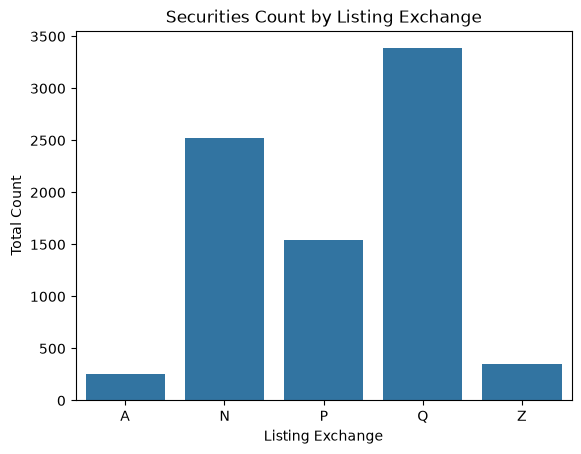

In [41]:
sns.barplot(x=go.index, y=go.values)


plt.title('Securities Count by Listing Exchange')
plt.xlabel('Listing Exchange')
plt.ylabel('Total Count')
plt.show()

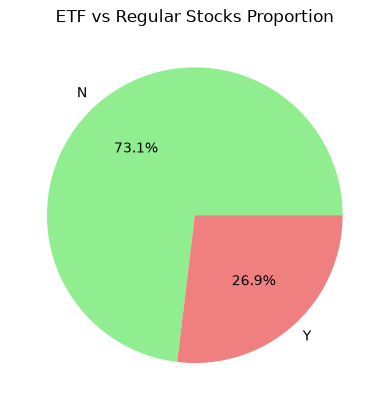

In [ ]:
etf_counts = df['ETF'].value_counts()
etf_counts.plot(kind='pie', autopct='%1.1f%%', colors=['lightgreen', 'lightcoral'])
plt.title('ETF vs Regular Stocks Proportion')
plt.show()

In [43]:
gold_stocks = df[df['Security Name'].str.contains('Gold', case=False, na=False)]
gold_stocks.head()

,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,Y,100.0,N,Unknown,AAAU,AAAU,N
158,Y,AGI,Alamos Gold Inc. Class A Common Shares,N,,N,100.0,N,Unknown,AGI,AGI,N
225,Y,AKG,Asanko Gold Inc.,A,,N,100.0,N,Unknown,AKG,AKG,N
261,Y,ALO,Alio Gold Inc. Common Shares (Canada),A,,N,100.0,N,Unknown,ALO,ALO,N
459,Y,ASA,ASA Gold and Precious Metals Limited,N,,N,100.0,N,Unknown,ASA,ASA,N


In [44]:
p_exchange_etfs = df[(df['ETF'] == 'Y') & (df['Listing Exchange'] == 'P')]

p_exchange_etfs.head()

,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,Y,100.0,N,Unknown,AAAU,AAAU,N
4,Y,AADR,AdvisorShares Dorsey Wright ADR ETF,P,,Y,100.0,N,Unknown,AADR,AADR,N
24,Y,ABEQ,Absolute Core Strategy ETF,P,,Y,100.0,N,Unknown,ABEQ,ABEQ,N
66,Y,ACSG,Xtrackers MSCI ACWI ex USA ESG Leaders Equity ETF,P,,Y,100.0,N,Unknown,ACSG,ACSG,N
75,Y,ACWF,iShares Edge MSCI Multifactor Global ETF,P,,Y,100.0,N,Unknown,ACWF,ACWF,N


In [45]:
df['Round Lot Size'].value_counts()

Round Lot Size
100.0    8044
10.0        4
1.0         1
Name: count, dtype: int64

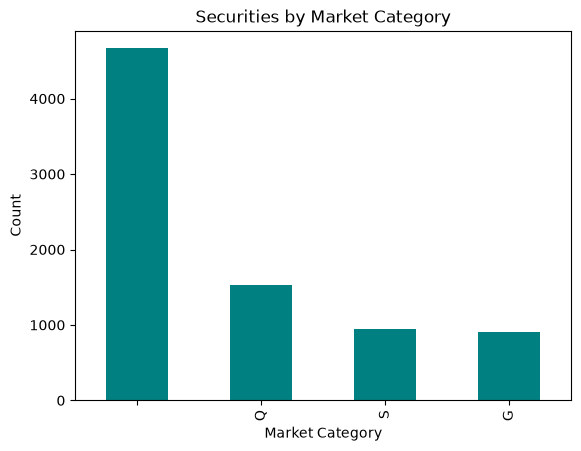

In [46]:
df['Market Category'].value_counts().plot(kind='bar', color='teal')
plt.title('Securities by Market Category')
plt.xlabel('Market Category')
plt.ylabel('Count')
plt.show()

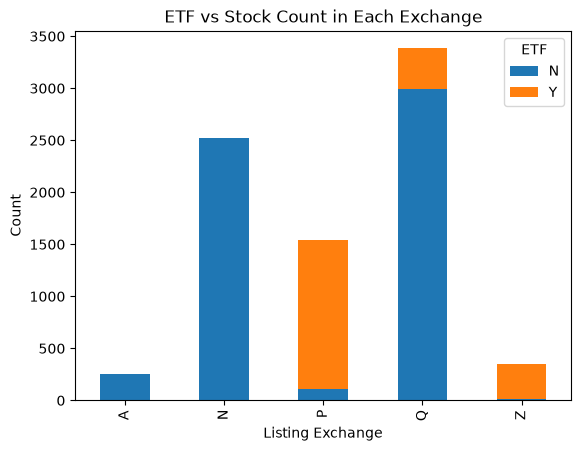

In [48]:
pd.crosstab(df['Listing Exchange'], df['ETF']).plot(kind='bar', stacked=True)
plt.title('ETF vs Stock Count in Each Exchange')
plt.ylabel('Count')
plt.show()